# 01. 데이터 구성 및 클래스 분포 분석

## 프로젝트 개요
| 항목 | 내용 |
|---|---|
| 과제 | 상품 이미지 기반 의류 카테고리 5종 분류 (원피스 / 재킷 / 바지 / 스커트 / 상의) |
| 데이터 | Fashion200K (Han et al., ICCV 2017) 기반 정제 데이터, 12,842장 |
| 비교 실험 | ResNet18 Scratch vs ImageNet Pretrained (Feature Extraction / Fine-tuning) |
| 평가 지표 | Macro F1, Accuracy, 클래스별 Recall, 혼동행렬 |

## 분석 목적
모델링 전 데이터 구성을 점검하여 평가 지표, 샘플링 전략, 누수 위험에 대한 의사결정 근거를 확보함.

## 핵심 결과
- 클래스 분포는 전 분할에서 거의 균형 (최대/최소 비율 ≈ 1.1) → 재표집·가중 손실 없이 시작
- 상품 단위 분할 확인, ID 기준 분할 간 누수 없음
- 단, 착용 모델·브랜드 단위 교차 가능성은 미검증 → 후속 점검 항목으로 분리

## 1. 데이터 로드

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_ROOT = Path("fashion_dataset")  
META_PATH = DATA_ROOT / "metadata.csv"
MAP_PATH = DATA_ROOT / "class_mapping.csv"
SPLITS = ["train", "val", "test"]

meta = pd.read_csv(META_PATH, encoding="utf-8-sig")
class_map = pd.read_csv(MAP_PATH, encoding="utf-8-sig")

print("metadata shape:", meta.shape)
display(class_map)
display(meta.head())

FileNotFoundError: [Errno 2] No such file or directory: 'fashion_dataset\\metadata.csv'

## 2. 이미지 경로 연결 및 파일 존재 여부 확인

`image_path`는 `images/train/xxx.jpg` 형태의 **데이터 폴더 기준 상대 경로**입니다.
폴더 구조가 `fashion_dataset/train/xxx.jpg`인 경우도 찾을 수 있도록 대체 경로를 둡니다.

클래스별 하위 폴더가 없으므로 `ImageFolder`가 아니라 **CSV 기반 Dataset**을 사용해야 합니다.

In [1]:
def resolve_path(row):
    p1 = DATA_ROOT / row["image_path"]
    if p1.exists():
        return p1
    p2 = DATA_ROOT / row["split"] / Path(row["image_path"]).name
    return p2 if p2.exists() else None

meta["full_path"] = meta.apply(resolve_path, axis=1)
missing = meta["full_path"].isna().sum()
print(f"찾지 못한 이미지: {missing} / {len(meta)}")
if missing:
    display(meta.loc[meta["full_path"].isna(), ["image_path", "split"]].head())

# 폴더 안 실제 파일 수와 CSV 행 수 비교
for s in SPLITS:
    folder = DATA_ROOT / "images" / s
    if not folder.exists():
        folder = DATA_ROOT / s
    n_files = len(list(folder.glob("*.jpg"))) if folder.exists() else 0
    n_csv = (meta["split"] == s).sum()
    print(f"[{s:5s}] 폴더 파일 수: {n_files:5d} | CSV 행 수: {n_csv:5d}")

NameError: name 'meta' is not defined

### 결과
- 메타데이터 12,842행 중 누락 이미지: 0 장
- 분할별 폴더 파일 수와 CSV 행 수 일치 여부: True

## 3. 분할별 클래스 분포

클래스 불균형이 심하면 Accuracy가 다수 클래스에 끌려가므로 재표집, 가중 손실, Macro F1 같은 대응이 필요합니다.
**이미지 수**, **비율(%)**, **최대/최소 클래스 비율**을 함께 봅니다.

In [4]:
order = class_map.sort_values("target_id")["category"].tolist()

img_counts = (pd.crosstab(meta["category"], meta["split"])
                .reindex(index=order, columns=SPLITS))
img_counts.loc["TOTAL"] = img_counts.sum()
print("=== 분할별 이미지 수 ===")
display(img_counts)

img_ratio = (pd.crosstab(meta["category"], meta["split"], normalize="columns")
               .reindex(index=order, columns=SPLITS) * 100).round(2)
print("=== 분할별 클래스 비율(%) ===")
display(img_ratio)

for s in SPLITS:
    c = img_counts.loc[order, s]
    print(f"[{s:5s}] 최대/최소 비율 = {c.max() / c.min():.3f} "
          f"({c.idxmax()} {c.max()} / {c.idxmin()} {c.min()})")

=== 분할별 이미지 수 ===


split,train,val,test
category,,,
dress,1736,346,533
jacket,1615,331,502
pants,1670,340,503
skirt,1834,362,558
top,1668,343,501
TOTAL,8523,1722,2597


=== 분할별 클래스 비율(%) ===


split,train,val,test
category,,,
dress,20.37,20.09,20.52
jacket,18.95,19.22,19.33
pants,19.59,19.74,19.37
skirt,21.52,21.02,21.49
top,19.57,19.92,19.29


[train] 최대/최소 비율 = 1.136 (skirt 1834 / jacket 1615)
[val  ] 최대/최소 비율 = 1.094 (skirt 362 / jacket 331)
[test ] 최대/최소 비율 = 1.114 (skirt 558 / top 501)


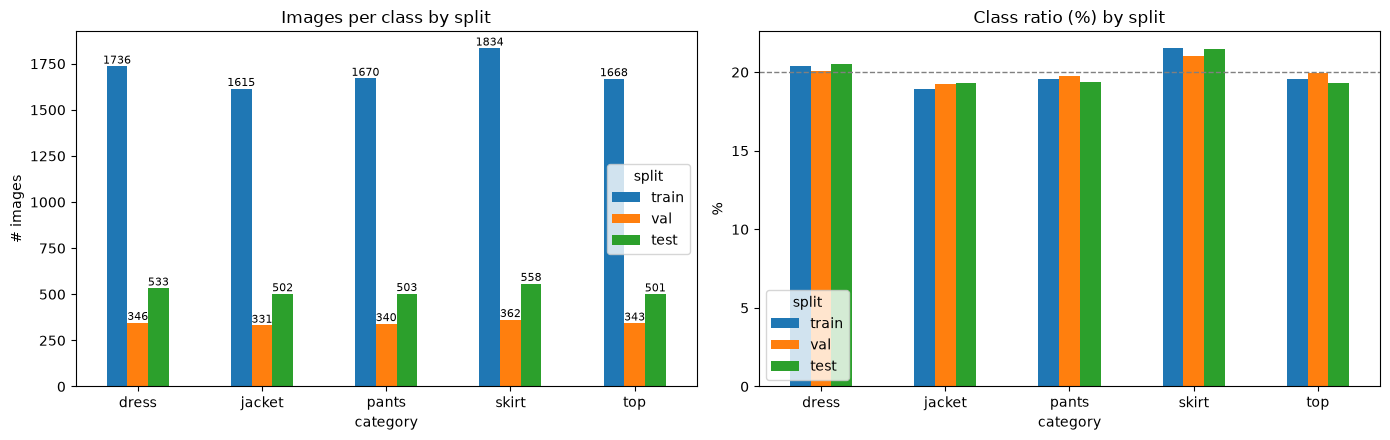

In [5]:
# 한글 폰트 문제를 피하려고 영문 category로 표시
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

img_counts.loc[order].plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Images per class by split")
axes[0].set_ylabel("# images")
for cont in axes[0].containers:
    axes[0].bar_label(cont, fontsize=8)

img_ratio.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Class ratio (%) by split")
axes[1].set_ylabel("%")
axes[1].axhline(20, ls="--", c="gray", lw=1)   # 5클래스 완전 균형 기준선

plt.tight_layout()
plt.show()

### 결과
| 클래스 | Train | Val | Test |
|---|---|---|---|
| dress | 1,736 | 346 | 533 |
| jacket | 1,615 | 331 | 502 |
| pants | 1,670 | 340 | 503 |
| skirt | 1,834 | 362 | 558 |
| top | 1,668 | 343 | 501 |
| **합계** | **8,523** | **1,722** | **2,597** |

- 분할 비율 Train : Val : Test ≈ 66 : 13 : 20
- 클래스 비율 19.0 ~ 21.5% (균형 기준 20%), 최대/최소 비율 1.09 ~ 1.14

### 판단
- 불균형이 경미하여 초기 실험은 클래스 재표집·가중 손실 없이 진행
- 분할 간 클래스 비율이 거의 동일하므로 Val 성능을 Test 성능의 대리 지표로 사용 가능
- 경미한 불균형에서도 특정 클래스 성능 저하를 감지하기 위해 Accuracy와 함께 Macro F1, 클래스별 Recall을 주 지표로 채택

## 4. 상품(product) 단위 분포

같은 상품의 여러 사진은 같은 분할에 들어갑니다.
이미지 수만 보면 상품 다양성을 놓칠 수 있으므로 **상품 수**와 **상품당 이미지 수**도 확인합니다.

In [6]:
prod_counts = (meta.groupby(["category", "split"])["product_id"].nunique()
                   .unstack().reindex(index=order, columns=SPLITS))
print("=== 분할별 상품 수 ===")
display(prod_counts)

imgs_per_prod = meta.groupby(["split", "product_id"]).size()
print("=== 상품당 이미지 수 ===")
display(imgs_per_prod.groupby(level="split").describe()[["mean", "min", "max"]])

=== 분할별 상품 수 ===


split,train,val,test
category,,,
dress,1000,200,300
jacket,998,200,299
pants,999,200,300
skirt,999,200,300
top,1000,200,300


=== 상품당 이미지 수 ===


,mean,min,max
split,,,
test,1.732488,1.0,2.0
train,1.705965,1.0,2.0
val,1.722000,1.0,2.0


### 결과
- 클래스별 상품 수: Train ≈ 1,000 / Val 200 / Test 300 (클래스 간 동일)
- 상품당 이미지 1 ~ 2장 (평균 약 1.7장)

### 판단
- 학습 데이터 축소 실험 시 이미지 단위가 아닌 **상품 단위 샘플링**을 적용하여, 동일 상품의 이미지가 분리되지 않도록 함

## 5. 분할 간 데이터 누수 점검

같은 상품이나 그룹이 Train과 Val/Test에 동시에 있으면, 모델이 **본 적 있는 상품**을 맞히는 셈이 되어 성능이 과대평가됩니다.

In [ ]:
for col in ["product_id", "group_id", "image_id"]:
    n_split = meta.groupby(col)["split"].nunique()
    leaked = n_split[n_split > 1]
    print(f"{col:10s}: 여러 분할에 걸친 값 {len(leaked)}개")

product_id: 여러 분할에 걸친 값 0개
group_id  : 여러 분할에 걸친 값 0개
image_id  : 여러 분할에 걸친 값 0개


### 결과
| 기준 | 복수 분할에 걸친 값 |
|---|---|
| product_id | 0 |
| group_id | 0 |
| image_id | 0 |

### 한계 및 후속 계획
- ID 기준 누수는 없으나, 데이터 명세상 **착용 모델·브랜드 단위 분할은 보장되지 않음**
- 같은 모델·배경·촬영 스튜디오가 분할 간 공유될 경우 성능이 과대평가될 수 있음
- 후속 점검: 이미지 임베딩 유사도 기반으로 분할 간 근접 중복(near-duplicate) 탐색

## 6. (참고) Train 하위분류 분포

클래스 **내부**의 다양성을 확인하는 용도입니다. 하위분류는 **모델 입력으로 사용하지 않습니다**.
나중에 오분류를 분석할 때, 어떤 하위분류가 자주 틀리는지 보는 데 활용합니다.
예를 들어 maxi skirt와 maxi dress, long-sleeved top과 jacket처럼 헷갈리기 쉬운 조합이 있습니다.

In [ ]:
sub = (meta[meta["split"] == "train"]
       .groupby(["category", "subcategory"]).size()
       .rename("images").reset_index()
       .sort_values(["category", "images"], ascending=[True, False]))
display(sub)

,category,subcategory,images
0,dress,casual_and_day_dresses,302
1,dress,cocktail_dresses,302
3,dress,maxi_and_long_dresses,300
5,dress,prom_and_formal_dresses,287
4,dress,mini_and_short_dresses,274
2,dress,gowns,271
7,jacket,casual_jackets,378
10,jacket,leather_jackets,342
6,jacket,blazers_and_suit_jackets,229
12,jacket,waistcoats_and_gilets,229


### 결과
- 클래스별 3 ~ 5개 하위분류가 비교적 고르게 분포 (예: skirt – mini / knee / mid / maxi)

### 오분류 가설 (오류 분석 단계에서 검증)
| 예상 혼동 | 근거 |
|---|---|
| maxi skirt ↔ maxi dress | 하체 중심으로 크롭된 경우 상의 정보 부족 |
| mini skirt ↔ mini dress | 동일 |
| long-sleeved top ↔ casual jacket | 소매·실루엣 유사, 여밈 구조 차이만 존재 |

### 판단
- 길이·소매·밑단이 핵심 판별 정보이므로, 추가 Crop보다 **종횡비 유지 Resize + Padding**을 기본 전처리로 채택### 📝 정리
- 클래스마다 3~4개의 하위분류가 비교적 고르게 분포합니다.
  - 예: skirt는 knee / mid / mini / maxi, dress는 casual / cocktail / maxi / prom / mini 등입니다.
- **혼동이 예상되는 조합**
  - maxi_skirts ↔ maxi_and_long_dresses: 하의만 크롭된 경우 구분이 어렵습니다.
  - long_sleeved_tops ↔ casual_jackets
  - mini_skirts ↔ mini_and_short_dresses
  - cropped_pants ↔ leggings: 같은 클래스라 문제는 아니지만, 형태 다양성이 큽니다.
- 추가 Crop을 하면 **길이·소매·밑단** 정보가 손실될 수 있습니다. 그래서 종횡비를 유지한 Resize+Padding이 출발점으로 적절합니다.

## 요약 및 의사결정
| 항목 | 결과 | 의사결정 |
|---|---|---|
| 클래스 분포 | 거의 균형 (≈ 1.1배) | 재표집 없이 시작, Macro F1 중심 평가 |
| 상품 구성 | 상품당 1 ~ 2장 | 데이터 축소 시 상품 단위 샘플링 |
| ID 누수 | 없음 | 제공 분할 유지 |
| 모델·브랜드 교차 | 미검증 | 임베딩 기반 근접 중복 점검 예정 |
| 혼동 예상 클래스 | skirt/dress, top/jacket | 전처리에서 길이 정보 보존, 오류 분석에서 검증 |

**Next**: 02. 이미지 크기·종횡비 분석 및 전처리 설계